# Hyderabad public charging-site inventory audit

This notebook analyzes mapped OpenStreetMap charging-site objects inside the query bounding box. It does **not** contain charger utilization, energy sales, customer, or demand observations. An OSM record means a charging station was mapped, not that it is currently operational or that the map is exhaustive.

Refresh the snapshot with `python scripts/fetch_real_data.py` when the Overpass API is available. The checked-in CSV is the snapshot captured on 2026-11-01.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / "data" / "reference").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "reference" / "charging_sites_openstreetmap.csv"
OUTPUT_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sites = pd.read_csv(DATA_PATH)
sites["latitude"] = pd.to_numeric(sites["latitude"], errors="coerce")
sites["longitude"] = pd.to_numeric(sites["longitude"], errors="coerce")
sites["capacity"] = pd.to_numeric(sites["capacity"], errors="coerce")
sites["display_name"] = sites["name"].fillna("").str.strip()
sites.loc[sites["display_name"].eq(""), "display_name"] = sites["brand"].fillna("").str.strip()
sites.loc[sites["display_name"].eq(""), "display_name"] = "Name not mapped"
print(f"Mapped charging-site objects in snapshot: {len(sites):,}")
print(f"Snapshot timestamp: {sites['snapshot_utc'].dropna().iloc[0]}")
display(sites)

Mapped charging-site objects in snapshot: 3
Snapshot timestamp: 2026-11-01T06:57:20Z


,osm_type,osm_id,name,brand,operator,network,latitude,longitude,access,capacity,source_url,snapshot_utc,license,display_name
0,node,3612553734,NaN,NaN,NaN,NaN,17.364959,78.474929,NaN,NaN,NaN,2026-11-01T06:57:20Z,Open Database License (ODbL),Name not mapped
1,node,12990861171,NaN,TGRedCo,NaN,NaN,17.494381,78.349999,yes,1.0,https://www.openstreetmap.org/node/12990861171,2026-11-01T06:57:20Z,Open Database License (ODbL),TGRedCo
2,way,1299079174,NaN,FreshBus Charging Point,NaN,NaN,17.404811,78.333340,private,NaN,https://www.openstreetmap.org/way/1299079174,2026-11-01T06:57:20Z,Open Database License (ODbL),FreshBus Charging Point


## Data quality and coverage

Missing tags indicate missing OpenStreetMap attributes, not necessarily missing information at the physical site. The query searches OSM objects tagged `amenity=charging_station` within 17.15–17.65° N, 78.15–78.70° E.

In [2]:
assert sites["osm_id"].is_unique
assert sites["latitude"].between(17.15, 17.65).all()
assert sites["longitude"].between(78.15, 78.70).all()

quality = pd.DataFrame(
    {
        "Mapped objects": [len(sites)],
        "Objects with name or brand": [sites["display_name"].ne("Name not mapped").sum()],
        "Objects with access tag": [sites["access"].notna().sum()],
        "Objects with capacity tag": [sites["capacity"].notna().sum()],
        "Objects with coordinates": [sites[["latitude", "longitude"]].notna().all(axis=1).sum()],
    }
).T.rename(columns={0: "Count"})
quality["Share of mapped objects (%)"] = (quality["Count"] / len(sites) * 100).round(1)
display(quality)

tag_coverage = pd.DataFrame(
    {
        "Tag": ["name", "brand", "operator", "network", "access", "capacity"],
        "Rows populated": [sites[column].fillna("").astype(str).str.strip().ne("").sum() for column in ["name", "brand", "operator", "network", "access", "capacity"]],
    }
)
tag_coverage["Rows missing"] = len(sites) - tag_coverage["Rows populated"]
display(tag_coverage)

,Count,Share of mapped objects (%)
Mapped objects,3,100.0
Objects with name or brand,2,66.7
Objects with access tag,2,66.7
Objects with capacity tag,1,33.3
Objects with coordinates,3,100.0


,Tag,Rows populated,Rows missing
0,name,0,3
1,brand,2,1
2,operator,0,3
3,network,0,3
4,access,2,1
5,capacity,1,2


## Mapped-site coordinate plot

This is a coordinate scatter plot, **not** a basemap or a complete station-coverage map. Use the linked OpenStreetMap object pages for source context.

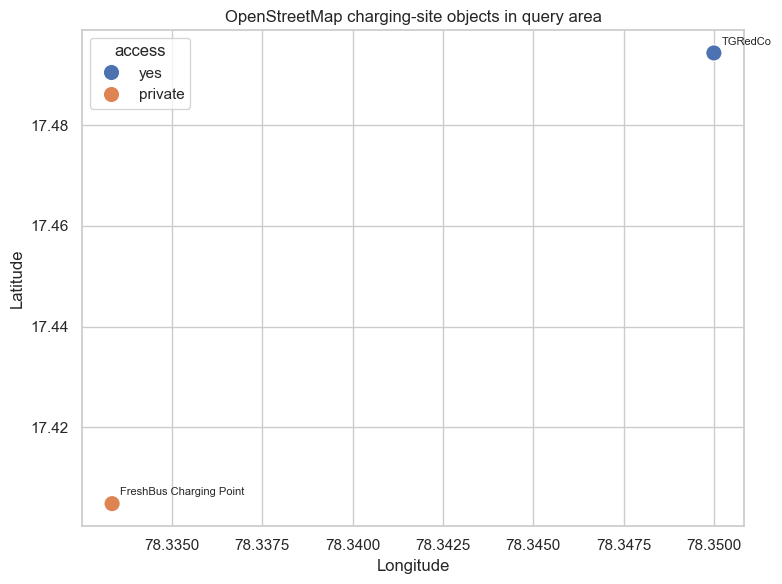

Saved analysis-ready data to C:\Users\DELL\Desktop\Hyderabad Ev Analytics\data\processed
Saved coordinate plot to C:\Users\DELL\Desktop\Hyderabad Ev Analytics\reports\figures


In [3]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=sites, x="longitude", y="latitude", hue="access", s=140, ax=ax)
for row in sites.itertuples():
    ax.annotate(row.display_name, (row.longitude, row.latitude), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.set(title="OpenStreetMap charging-site objects in query area", xlabel="Longitude", ylabel="Latitude")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "mapped_sites_coordinates.png", dpi=160)
plt.show()

sites.to_csv(OUTPUT_DIR / "charging_sites_audited.csv", index=False)
quality.to_csv(OUTPUT_DIR / "charging_sites_data_quality.csv")
print(f"Saved analysis-ready data to {OUTPUT_DIR}")
print(f"Saved coordinate plot to {FIGURES_DIR}")

## Interpretation and limitations

The result describes OSM tagging coverage within a bounding box, not the full Hyderabad charging network. This public source contains no charging-session timestamps, electricity delivered, tariffs, utilization, outages, or queue lengths. Therefore demand forecasting, revenue analysis, and capacity recommendations are not supported by this dataset and are intentionally not reported. For those analyses, obtain operator or government session-level data with permission and document its coverage.